# Clustering packets of WPT using k-means method - applied to the synthetic data obtained by solving GA
This notebook produces the figures used in the **paper**, using the results of processed synthetic signals. Here we use average enerhy, spectral entropy, kurtosis and log-energy for k-means clustering and thresholding. 

In [1]:
import sys
if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")
import os
import pickle

FILE_PATH = os.path.abspath(".")
RELATIVE_PATH = "./paper2024_results/"
folder_path = os.path.abspath(os.path.join(FILE_PATH, RELATIVE_PATH))

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import pandas as pd
from wavelet_transform.utils.save_plots import save_figure

import numpy as np
import wavelet_transform.utils.wavelet_features as extract
import wavelet_transform.utils.bubble_data_manager as bdm
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.extensions import fft, to_dB, psd, trim_data
from wavelet_transform.utils.machine_learning import fit_k_means #,fit_and_evaluate, assess_parameter
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.preprocessing import preprocess, add_noise
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD
from wavelet_transform.wpt.transform import Transform

### Parameters
Specify parameters for solving GA and generating synthetic data, and performing wavelet transform. The ultrasound parameters are fixed at 1MHz and 1MPa. Three secarios are considered for the paper, as shown below:
1. transient cavitation with multiple ultrea- and harmonics + BB: r_init = 0.5e-6
2. transient cavitation with BB: r_init = 5e-6
3. stable cavitation: r_init = 50e-6


In [3]:
# Set the sonication pulse parameters
pac = 1e6  # the amplitude of the sine wave in Pa
frequency = 1.1 * 1e6  # insonation frequency (Hz)
period = 1 / frequency # the period of the acoustic wave at the fundamental frequency 
n_cycles = 100  # no. of cycles of the sine wave
parameters = {
    "time_delay": 0 * period,  # time delay, t1
    "pulse_width": 1000*n_cycles * period,  # pulse width, W = 1 / Q
    "phase_initial": 0 * period,  # tau
    "phase_shift": 0, #np.pi / 4,  # phi
    "no_harmonics": 1,   # k
    "Rdot_init": 0,  # initial bubble's wall velocity in m/s
}

# Set sampling rate and noise std
sampling_rate = frequency * 1e2# sampling rate to generate the time vector
signal2noise = 30

r_measure = 1e-4 # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

The R0 (initial bubble radius) values are defined below. We consider the sonication parameters to be fixed and different stable and transient cavitation scenarios are designed by only changing the initial bubble radius.  

In [4]:
# Scenario 1: transient with multiple ultra- and harmonics + broadband in acoustic emission
Rinit1 = 0.5e-6  # initial bubble radius in meters
# Scenario 2: transient with a harmonic + broadband in acoustic emission
Rinit2 = 3.4e-6  # initial bubble radius in meters
# # Scenario 3: stable with a harmonic in acoustic emission
# Rinit3 = 15e-6  # initial bubble radius in meters
# Scenario 4: stable with fundamental only in acoustic emission
Rinit4 = 50e-6  # initial bubble radius in meters
Rinit_list = [Rinit1, Rinit2, Rinit4]
n_cases = len(Rinit_list)

Rinit_dict = {}
for r_init in Rinit_list:
    Rinit_dict['R0:'+str(r_init*1e6)+'μm'] = r_init

result_id = "_".join(Rinit_dict.keys())+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
print(result_id)

results_df = [{"t": [],
               "data": [],
               "data_preprocessed":[],
               "t_data_truncated":[],
               "data_truncated":[],
               "wpt_df":[], 
               "wpt_df_train":[],
               "tr_obj":[],
               "spectrum":[],
               "spectrum_freq":[],
               "kmeans":[],
               "labels":[],
               "labels_sorted":[],
               "centers":[],
               "data_train":[],
               "data_train_normalised":[], 
               "centers":[], 
               "centers_scaled":[],
               "centers_sorted":[],
               "Rinit":list(Rinit_dict.values())[i],
               "legend": list(Rinit_dict.keys())[i]}
              for i in range(n_cases) ]

R0:0.5μm_R0:3.4μm_R0:50.0μm_freq:1.1MHz_Pac:1.0MPa


Setting the wavelet transform parameters and saving/export flag:

Setting the export flags - for figs and results:

In [5]:
savefig_flag = False
save_results_flag = False

Producing and plotting the wavelet and scaling functions for the selected wavelet family:

In [6]:
Font_Size = 24
Tick_Size = 24
Fig_Height = 400
Fig_Width = 800

### Generating acoustic emission data by solving Gilmore-Akulichev model
Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). The parameters are defined above. 

In [7]:
# BUBBLE DYNAMICS DATA
data_t_tuples = []
data_t_trimmed_tuples = []
data_preprocessed_list = []
i = 0
for Rinit in Rinit_list:
    data_tmp, t_tmp = bdm.get_data(
        Rinit, frequency, pac, sampling_rate, n_cycles=n_cycles, r_measure=r_measure,
        return_time=True, **parameters
    )
    # Add noise
    data_tmp = add_noise(data_tmp, signal2noise)
    # Normalise
    data_preprocessed = preprocess(data_tmp, window=False)
    data_preprocessed_list.append(data_preprocessed)
    # Trimming data for visualisation
    data_trunc, t_data_trunc = trim_data(data_preprocessed, t_tmp, (0*period, 7*period), return_time=True)
    data_t_trimmed_tuples.append([data_trunc, t_data_trunc])
    data_t_tuples.append([data_tmp,t_tmp])
    psd_amp, psd_freq = psd(data_preprocessed, sampling_rate, frequency)
    results_df[i]['data_truncated']= data_trunc
    results_df[i]['t_data_truncated'] = t_data_trunc
    results_df[i]['data_preprocessed'] = data_preprocessed
    results_df[i]['t'] = t_tmp
    results_df[i]['data'] = data_tmp
    results_df[i]['spectrum_freq'] = psd_freq
    results_df[i]['spectrum'] = psd_amp
    i+=1
    

Plotting the acoustic emissions and their spectra. The truncated signals and their spectra are used in the paper.

In [8]:
data_t_df = pd.concat( [pd.DataFrame(
    data={
        "t": data_t_tuples[i][1]/period,
        "data": data_t_tuples[i][0],
        "legend": list(Rinit_dict.keys())[i],
    }
) for i in range(n_cases) ])

data_t_trimmed_df = pd.concat( [pd.DataFrame(
    data={
        "t": data_t_trimmed_tuples[i][1]/period,
        "data": data_t_trimmed_tuples[i][0],
        "legend": list(Rinit_dict.keys())[i],
    }
) for i in range(n_cases) ])


In [9]:
fig = px.line(data_t_df,x="t", y="data", color="legend")
fig.update_layout(
    height=Fig_Height,
    width=Fig_Width,
    xaxis=dict(title="t/period [DL]"),
    yaxis=dict(title="Radiated pressure /p<sub>0</sub> [DL]"),
)
fig.show()

In [10]:
from itertools import cycle, islice
lines = ['dot', 'dashdot', 'solid','dot', 'dash',  'longdash','longdashdot']
colours = ['blue','red','black','cyan','green']
linestyles = cycle(lines)
colournames = cycle(colours)
fig_ae = go.Figure()
# for i in range(2):
#     fig.add_trace( 
#         go.Scatter(x=data_t_trimmed_tuples[i][1]/period, y=data_t_tuples[i][0], line=dict(dash=dash_ops[i]), name=Rinit_list[i])
#     )

for i in range(n_cases):
    fig_ae.add_trace( 
        go.Scatter(x=results_df[i]['t_data_truncated']/period, y=results_df[i]['data_truncated'], 
                   line=dict(dash=next(linestyles),color=next(colournames)), name=results_df[i]['legend'])
    )
    
fig_ae.update_layout(
    height=Fig_Height,
    width=Fig_Width,
    font_size=Font_Size,
    xaxis=dict(title="t/T [DL]",tickfont = dict(size=Tick_Size)),
    yaxis=dict(title="P<sub>rad</sub> / P<sub>0</sub> [DL]",tickfont = dict(size=Tick_Size)),
    plot_bgcolor='white',
    legend=dict(
        x=0.0,
        y=1,
        traceorder='normal',
        font=dict(size=Font_Size,),
    ),
    legend_title=None,
    margin=go.layout.Margin(
        l=0, #left margin
        r=0, #right margin
        b=0, #bottom margin
        t=0  #top margin
    )
)
fig_ae.update_xaxes(
    mirror=True,
    ticks='outside',
    showline=True,
    linecolor='black',
    gridcolor='lightgrey'
)
fig_ae.update_yaxes(
    mirror=True,
    ticks='outside',
    showline=True,
    linecolor='black',
    gridcolor='lightgrey'
)
fig_ae.show()

if savefig_flag:
    print("figure name: " + "GA_calculated_emissions_"+result_id)
    save_figure(fig_ae, "GA_calculated_emissions_"+result_id, folder_path)
    

In [11]:
fft_lim = 10 # this is the upper limit for plotting the spectrum (fft/psd of emissions)
fig_psd = go.Figure()
linestyles = cycle(lines)
colournames = cycle(colours)

for i in range(n_cases):
    fig_psd.add_trace( 
        go.Scatter(x=results_df[i]['spectrum_freq'], y=10*np.log10(results_df[i]['spectrum']), 
                   line=dict(dash=next(linestyles),color=next(colournames)), name=results_df[i]['legend'])
    )
        
fig_psd.update_layout(
    height=Fig_Height,
    width=Fig_Width,
    font_size=Font_Size,
    xaxis=dict(title="f / f<sub>0</sub> [DL]",tickfont = dict(size=Tick_Size), range=[0, fft_lim]),
    yaxis=dict(title="Amplitude [dB]",tickfont = dict(size=Tick_Size),range=[-40,50]),
    plot_bgcolor='white',
    legend=dict(
        x=0.7,
        y=1,
        traceorder='normal',
        font=dict(size=Font_Size,),
    ),
    legend_title=None,
    margin=go.layout.Margin(
        l=0, #left margin
        r=0, #right margin
        b=0, #bottom margin
        t=0  #top margin
    )
)
fig_psd.update_xaxes(
    mirror=True,
    ticks='outside',
    showline=True,
    linecolor='black',
    gridcolor='lightgrey'
)
fig_psd.update_yaxes(
    mirror=True,
    ticks='outside',
    showline=True,
    linecolor='black',
    gridcolor='lightgrey'
)

fig_psd.show()
if savefig_flag:
    print("figure name: " + "spectrum_GA_calculated_emissions_"+result_id)
    save_figure(fig_psd, "spectrum_GA_calculated_emissions_"+result_id, folder_path)

In [12]:
# Parameters for the wavelet transform
wavelet = ["db20", "db20", "db20"]
levels = None  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
n = 4
min_level = [n, n, n]
freq_threshold = 1 # n10e6 / (sampling_rate / 2)  # the nodes with norm_freq_range above this threshold will not be kept

keep_ratio = "valid"

threshold = 3.2

In [13]:
# k-means parameters
kmeans_params = {
    "init": "k-means++",
    "n_init":20,
    "max_iter":1000,
    "tol":1e-20,
    "verbose":0,
    "algorithm":"lloyd",
}

# training data
classifying_metrics = [
    "log average energy",
    "kurtosis",
    "spectral entropy",
    "average energy",
    # "level entropy",
    # "skewness"
    # "entropy",
    # "crest factor",
]
# Set to None to select optimal number of clusters by silhouette score
use_inverse_metrics = False
inv_keep_ratio = 1  # keep ratio for inverse defined only for float input


## Wavelet transform of the preprocessed signal


In [14]:
for i in range(n_cases):
    results_df[i]['wpt_df'], results_df[i]['tr_obj'] = extract.extract_wavelet_features(
        results_df[i]['data_preprocessed'], levels, wavelet[i], mode, 
        include_tr_obj=True, min_entropy=use_min_entropy,
        min_level=min_level[i], freq_threshold=freq_threshold,
        keep_ratio=keep_ratio
    )

### Heisenberg visualisation
Making the Heisenberg plot of the dwpt transform

In [15]:
# tr_obj.calc_frequencies(sampling_rate)
# fig = plot.heisenberg(tr_obj, max(t_plot), padding="interpolate", use_log_scale=False)

# for i in range(n_cases):
#     tr_obj = results_df[i]['tr_obj']
#     tr_obj.calc_frequencies(sampling_rate)
#     fig_hbg = plot.heisenberg(
#         tr_obj, 1/sampling_rate*len(tr_obj.data), max_freq=fft_lim*0.0205, 
#         padding="repeat", use_log_scale=True, title=results_df[i]['legend'], vmin = -2, vmax = 1, color_map='viridis'
#     )
#     if savefig_flag is True:
#         fig_hbg_name="Heisenberg_GA_calculated_emissions_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
#         print("figure name: " + fig_hbg_name)
#         save_figure(fig_hbg, fig_hbg_name, folder_path)

### K-means

k-means clustering on the calculated statistics from the output of the DWPT. The classification metrics used in the paper are: 
    "average energy",
    "kurtosis",
    "log average energy",
    "spectral entropy".

### K-means without PCA

In [16]:
def clustering(results_df, n_cases, no_clusters, classifying_metrics, kmeans_params, metric_sorting=classifying_metrics[0]):
    from wavelet_transform.postprocess.plotting import relabel
    for i in range(n_cases):
        wpt_df = results_df[i]['wpt_df']
        tr_obj = results_df[i]['tr_obj']
        
        if use_inverse_metrics is True:
            inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object instead
            wpt_df_train = inv_tr_obj.info(leaf_nodes=True, freq_threshold=freq_threshold, keep_ratio=inv_keep_ratio)
        else:
            wpt_df_train = wpt_df.copy()
        
        data_train, labels, data_train_normalised, centers, scaler, kmeans = fit_k_means(
            wpt_df_train, 
            classifying_metrics, 
            no_clusters=no_clusters, 
            kmeans_params=kmeans_params, 
        )
        centers_scaled = scaler.fit_transform(centers)
        centers_sorted, labels_sorted = relabel(labels, centers, metric_sorting, ascending=False)
        results_df[i]['labels']=labels
        results_df[i]['centers']=centers
        results_df[i]['labels_sorted']=labels_sorted
        results_df[i]['centers_sorted']=centers_sorted
        results_df[i]['kmeans']=kmeans
        results_df[i]['centers_scaled']=centers_scaled
        results_df[i]['data_train_normalised']=data_train_normalised
        results_df[i]['data_train']=data_train
        results_df[i]['wpt_df_train']=wpt_df_train

In [17]:
# Gather db parameters for storage
bd_params = {
    "frequency": frequency,
    "freq_threshold": freq_threshold,
    "fft_lim": fft_lim,
    "pac": pac,
}


# Plotting

Now, to further decompose the transient component, we let the Kmeans algorithm identify the numbers of cluisters based on the classifiers.

In [18]:
no_clusters = (3, 6)  # upeer bound non-inclusive e.g. 3,6 chooses between 3, 4, 5 clusters
clustering(
    results_df, n_cases, no_clusters, classifying_metrics, kmeans_params, metric_sorting="average energy"
)


In [19]:
display(results_df[0]['centers'])
display(results_df[0]['centers_sorted'])

,log average energy,kurtosis,spectral entropy,average energy
0,-2.559079,6.360420,0.691885,0.581839
1,12.324326,1.520819,0.380317,17.077825
2,-0.090471,3.778057,0.500569,1.114741
3,-2.579154,13.403513,0.739604,0.552185


,index,log average energy,kurtosis,spectral entropy,average energy
0,1,12.324326,1.520819,0.380317,17.077825
1,2,-0.090471,3.778057,0.500569,1.114741
2,0,-2.559079,6.360420,0.691885,0.581839
3,3,-2.579154,13.403513,0.739604,0.552185


In [20]:
label_map_details = []         
label_map_details_bar = []  
for i in range(n_cases):
    label_map_details.append(dict((j, f"Cluster {j}") for j in range(len(results_df[i]['centers_sorted']))))
    label_map_details_bar.append(dict((j, f"{j}") for j in range(len(results_df[i]['centers_sorted']))))
print(label_map_details)

[{0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3'}, {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3', 4: 'Cluster 4'}, {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3'}]


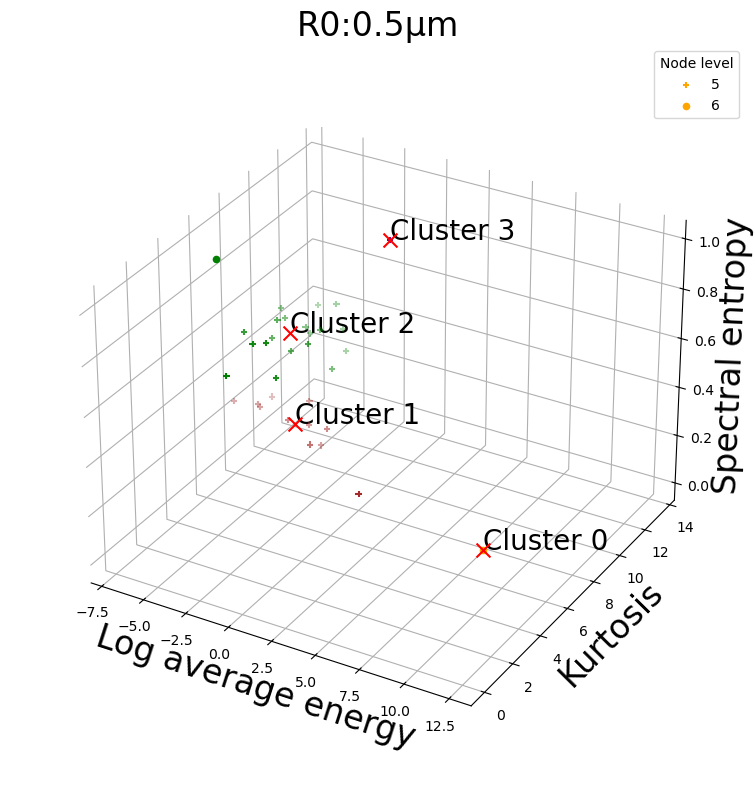

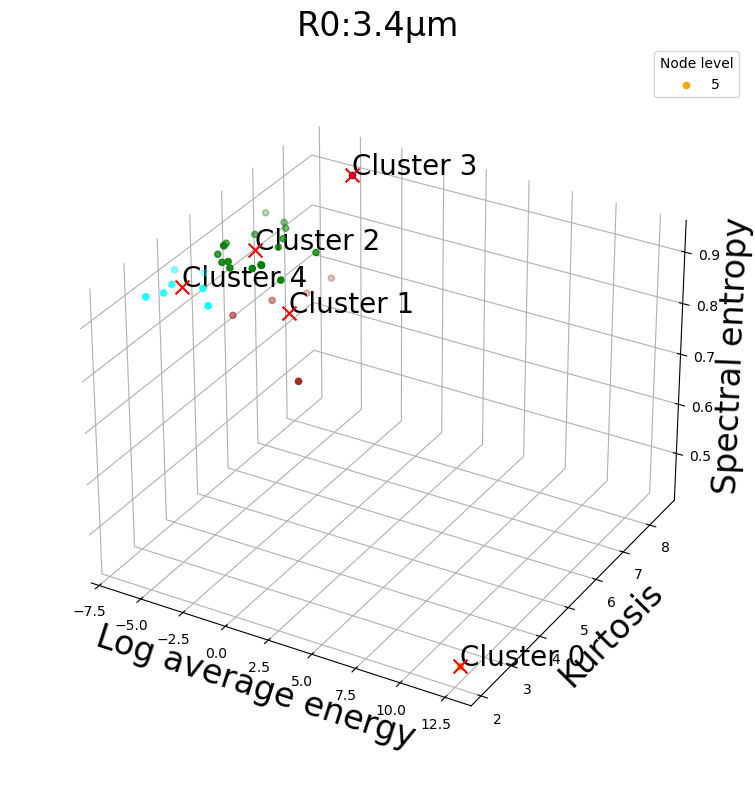

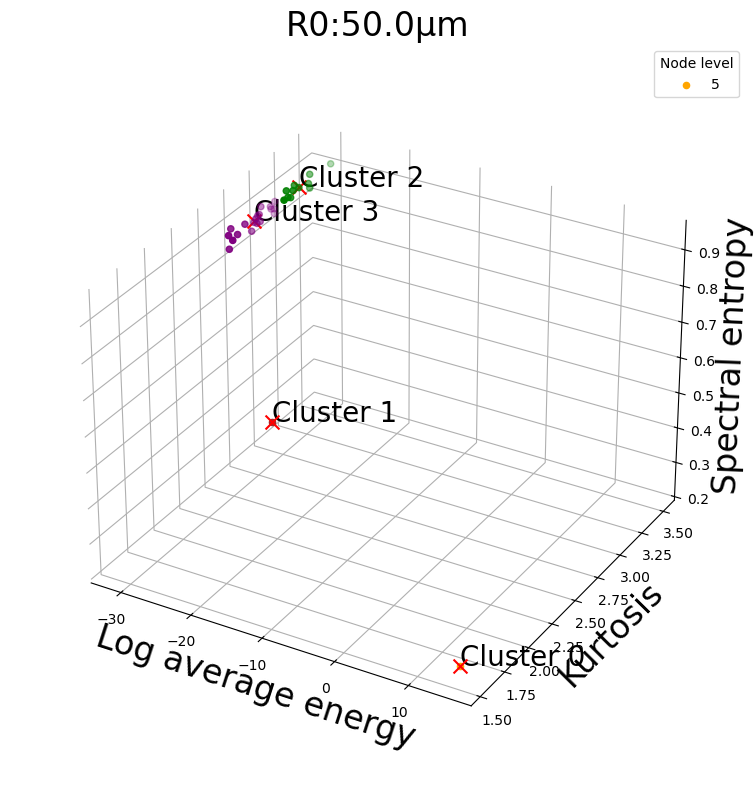

In [21]:
for i in range(n_cases):
    classifying_metrics = results_df[i]['data_train'].columns.to_list()
    fig_cls_arb = plot.plot_clustering(
        results_df[i]['data_train'],
        results_df[i]['centers_sorted'], 
        results_df[i]['labels_sorted'],
        metrics_to_plot=classifying_metrics,
        levels=results_df[i]['wpt_df_train']["level"].tolist(),
        label_map = label_map_details[i],
        title=results_df[i]['legend']
    )
    if savefig_flag:
        fig_cls_arb_name = "clusters_arbitrary_GA_calculated_emissions_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
        print("figure name: " + fig_cls_arb_name)
        save_figure(fig_cls_arb, fig_cls_arb_name, folder_path)
    

In [22]:
results_df[0]['centers_sorted'].shape[0]

4

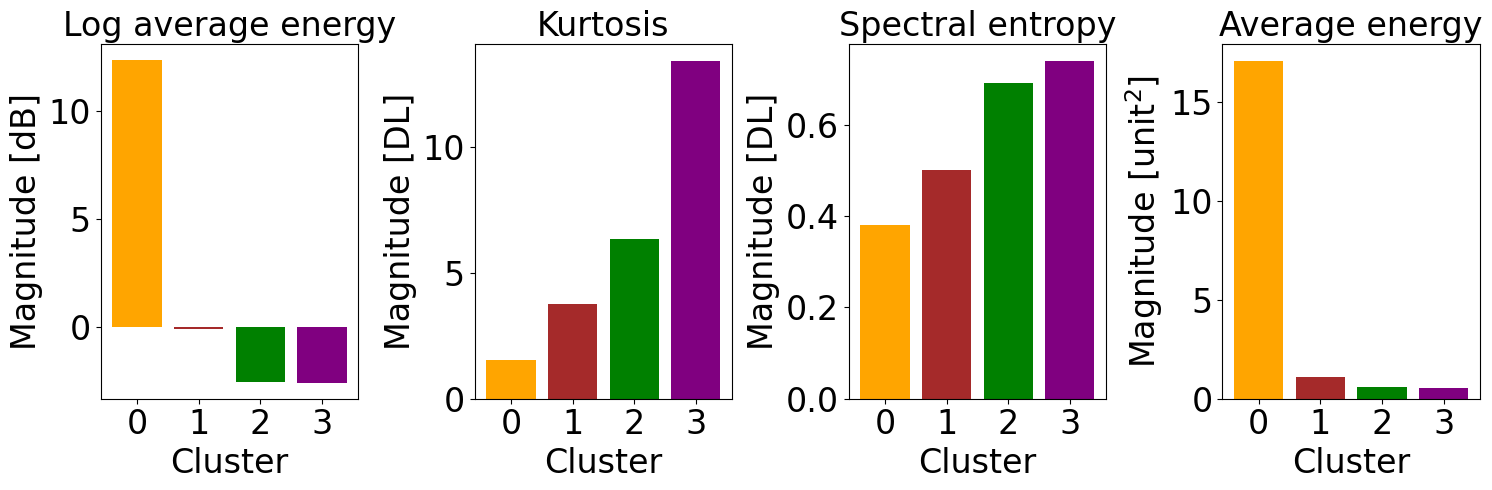

   index  log average energy   kurtosis  spectral entropy  average energy
0      1           12.324326   1.520819          0.380317       17.077825
1      2           -0.090471   3.778057          0.500569        1.114741
2      0           -2.559079   6.360420          0.691885        0.581839
3      3           -2.579154  13.403513          0.739604        0.552185


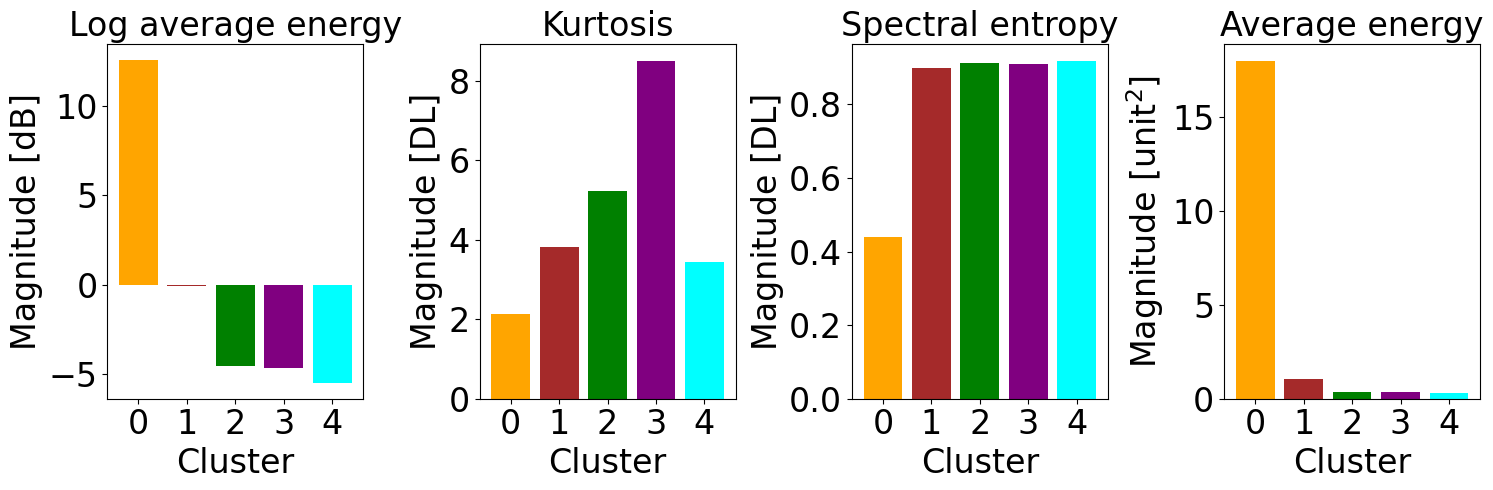

   index  log average energy  kurtosis  spectral entropy  average energy
0      1           12.548342  2.138133          0.439528       17.981845
1      4           -0.051541  3.826446          0.899270        1.072061
2      0           -4.530534  5.212862          0.914045        0.370791
3      3           -4.668790  8.487168          0.909319        0.341288
4      2           -5.485870  3.429339          0.917658        0.291915


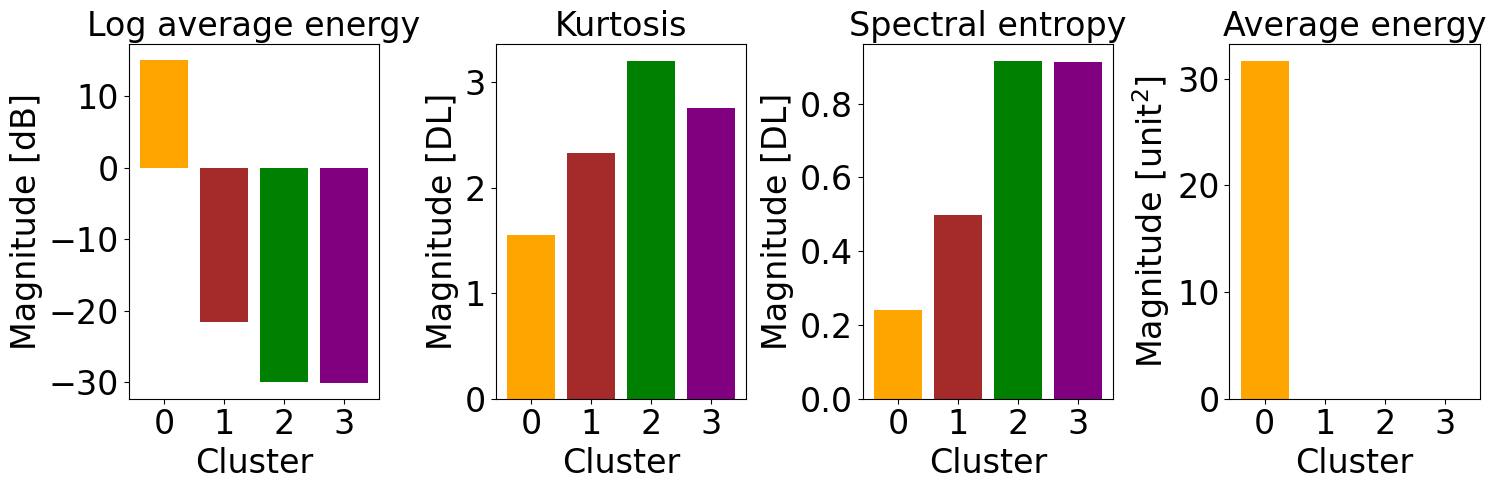

   index  log average energy  kurtosis  spectral entropy  average energy
0      1           15.002187  1.550139          0.240101       31.638702
1      3          -21.625466  2.329514          0.496896        0.006878
2      2          -29.938029  3.200308          0.914733        0.001016
3      0          -30.039352  2.753011          0.913749        0.000994


In [23]:
# Plot centroid metrics
for i in range(n_cases):
    fig_metric_arb = plot.plot_centers(results_df[i]['data_train'].columns.to_list(), 
                            results_df[i]['centers_sorted'],label_map=label_map_details_bar[i], xlabel_user = "Cluster"
                           )
    print(results_df[i]['centers_sorted'])
    
    if savefig_flag:
        fig_metric_arb_name="metrics_centroids_arbitrary_GA_calculated_emissions_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
        print("figure name: " + fig_metric_arb_name)
        save_figure(fig_metric_arb, fig_metric_arb_name, folder_path)

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

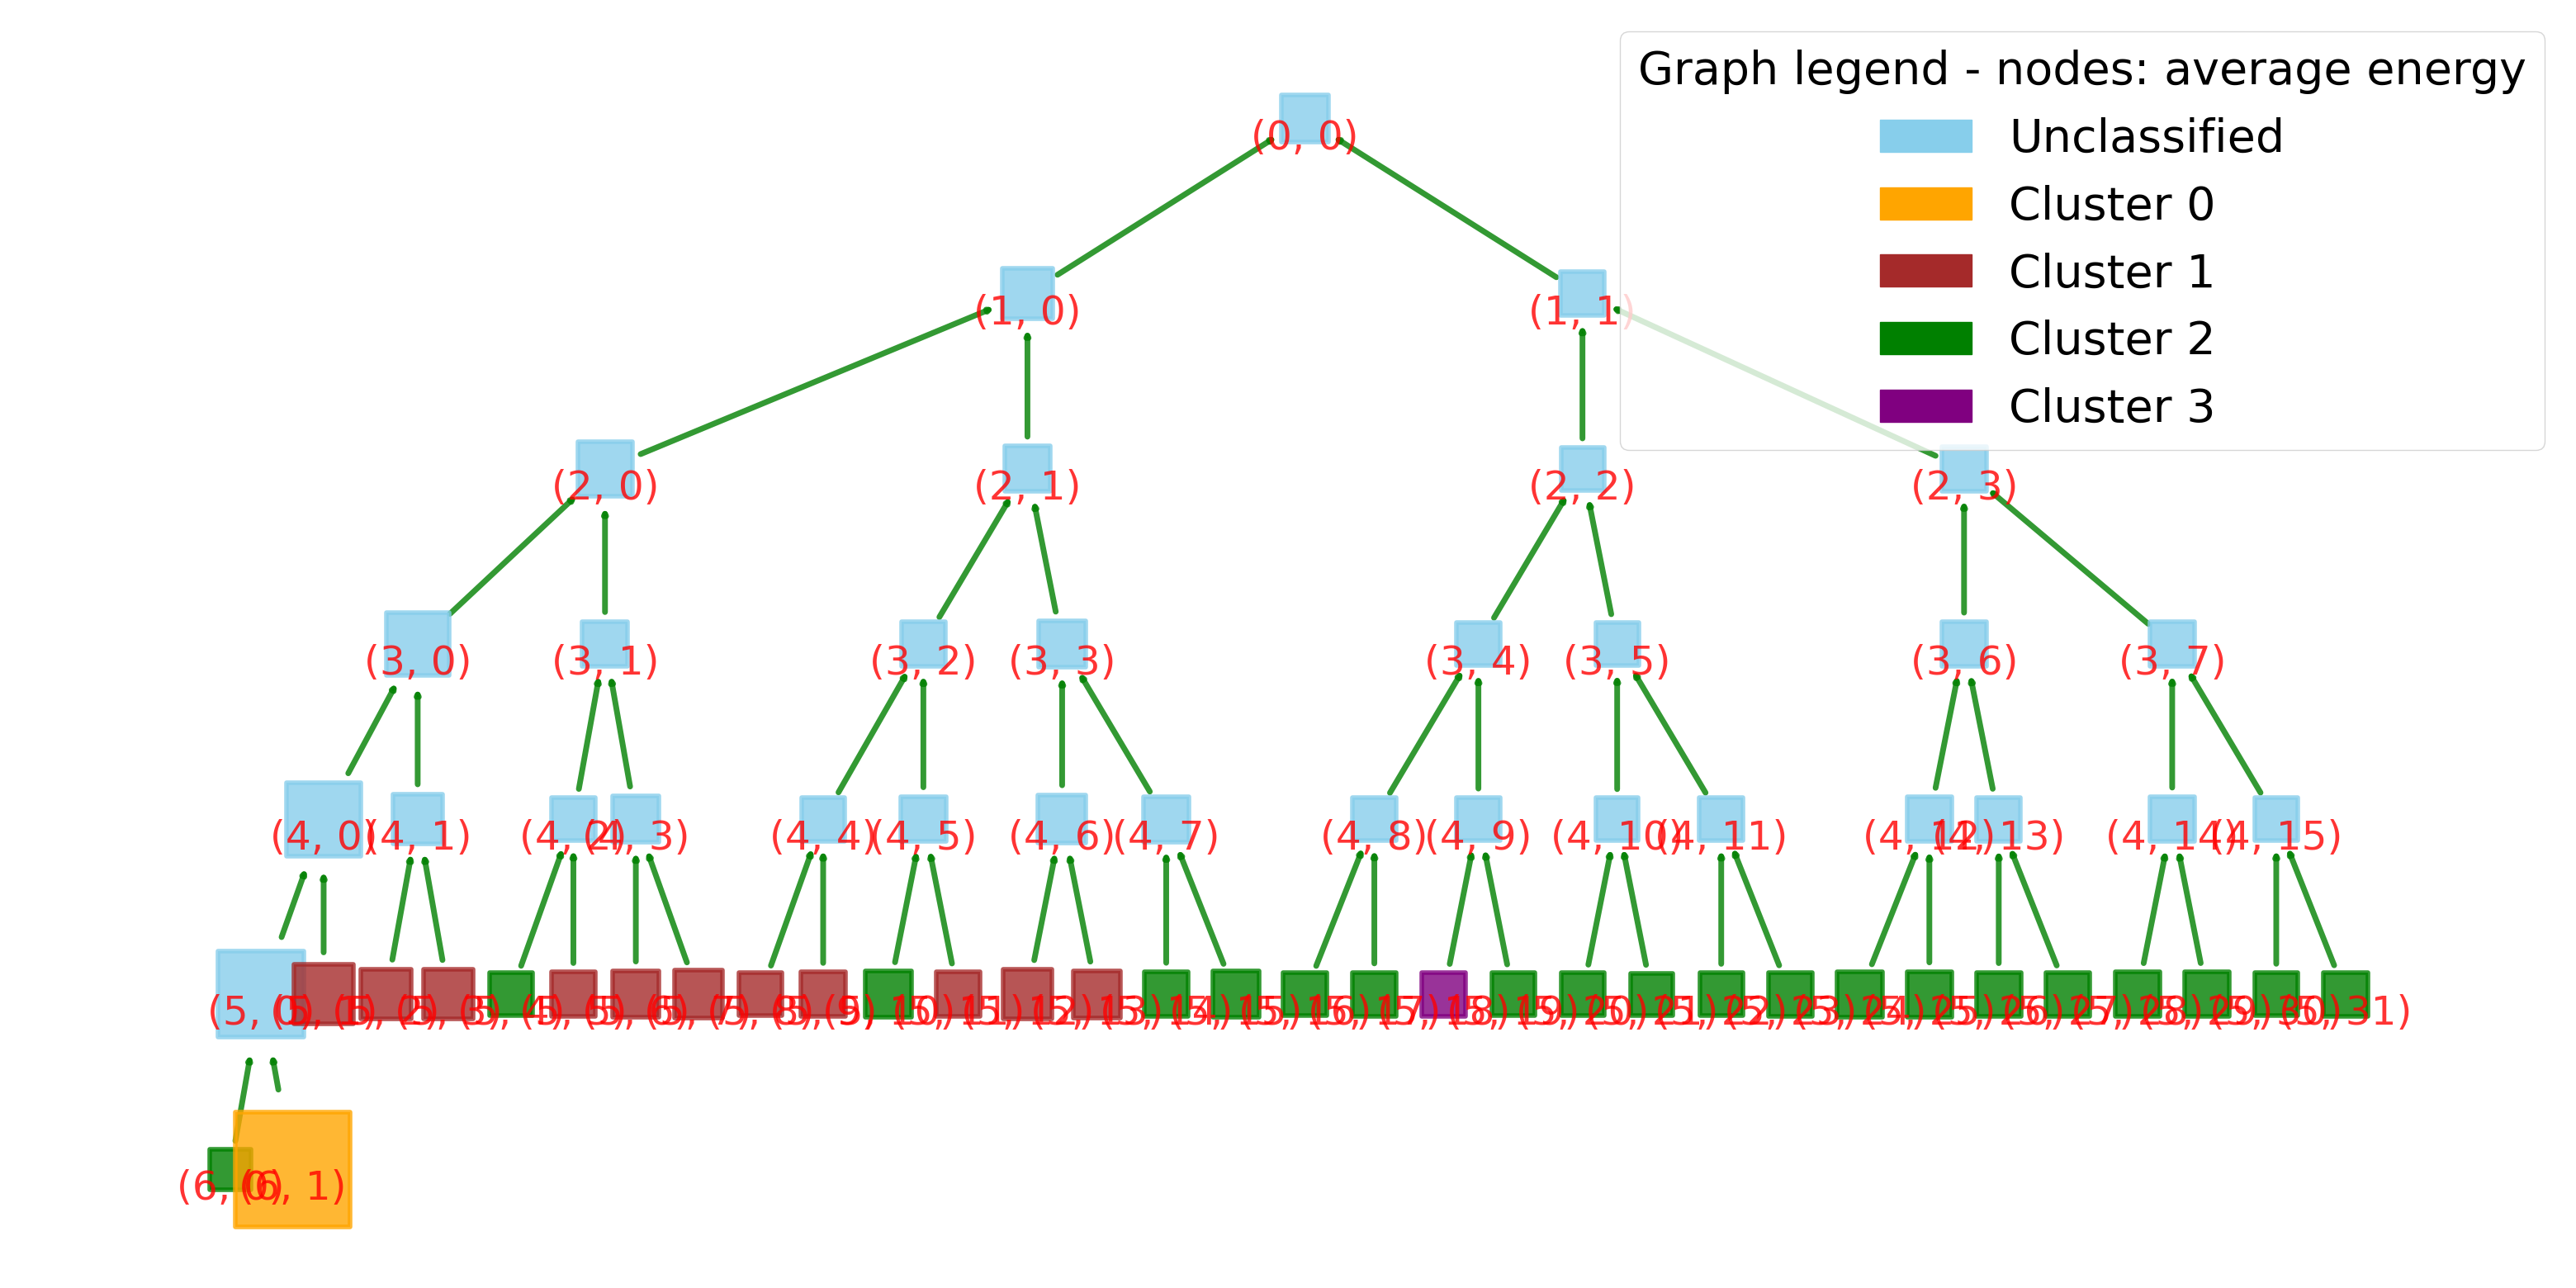

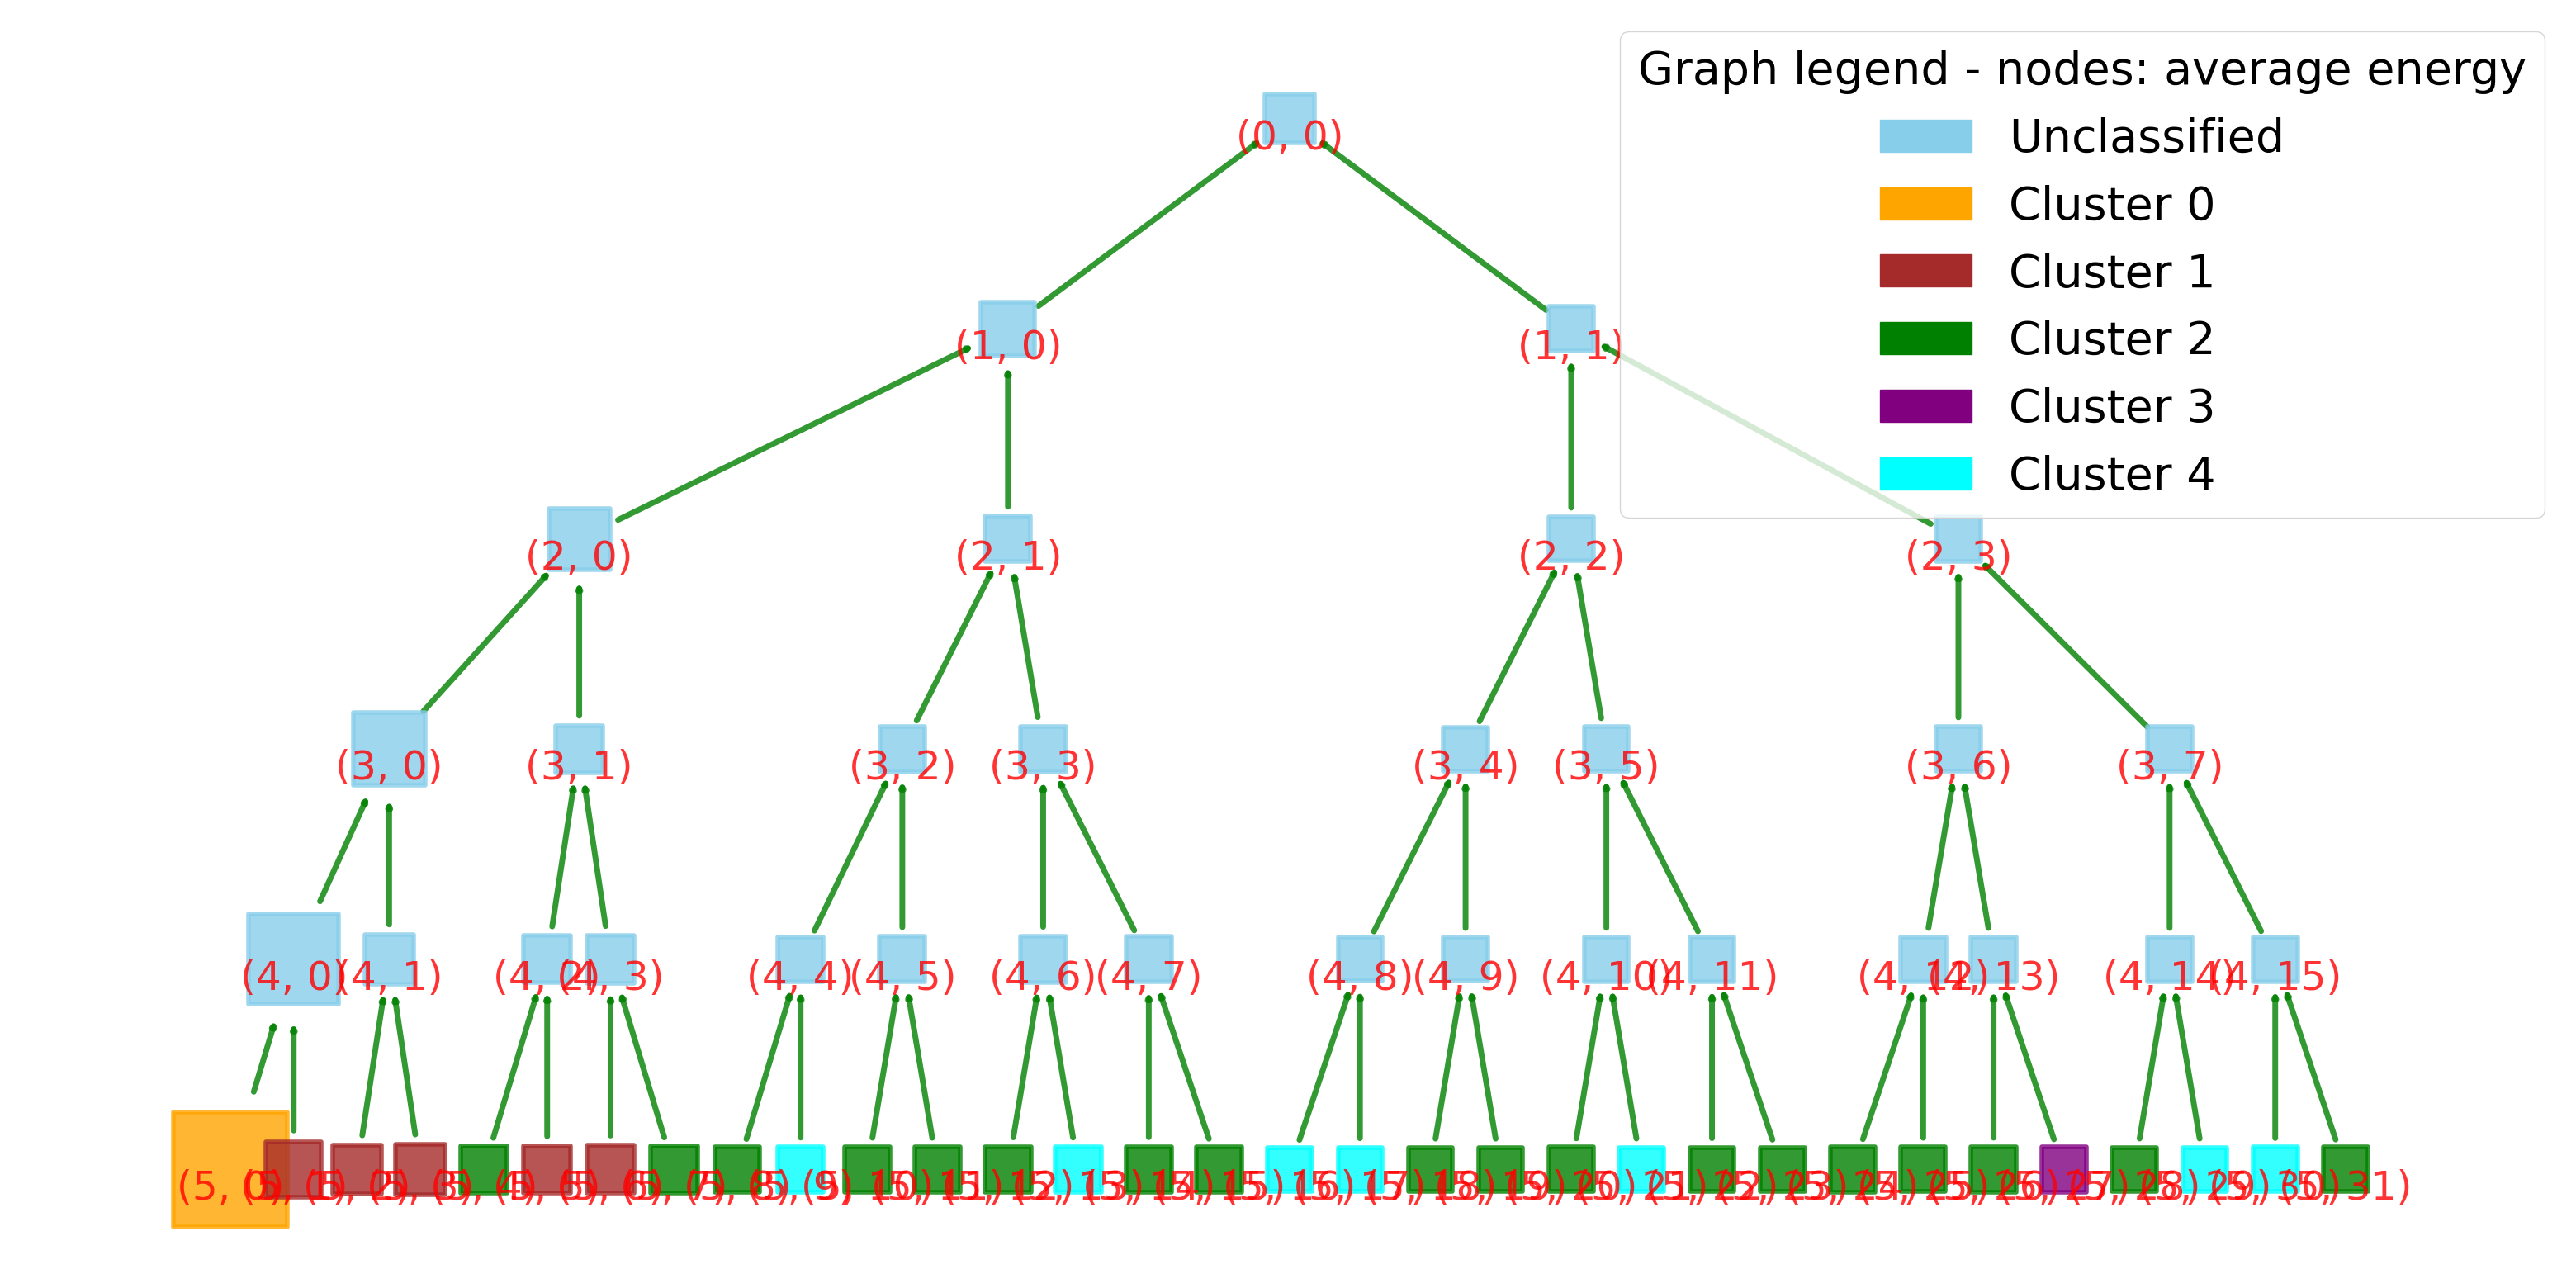

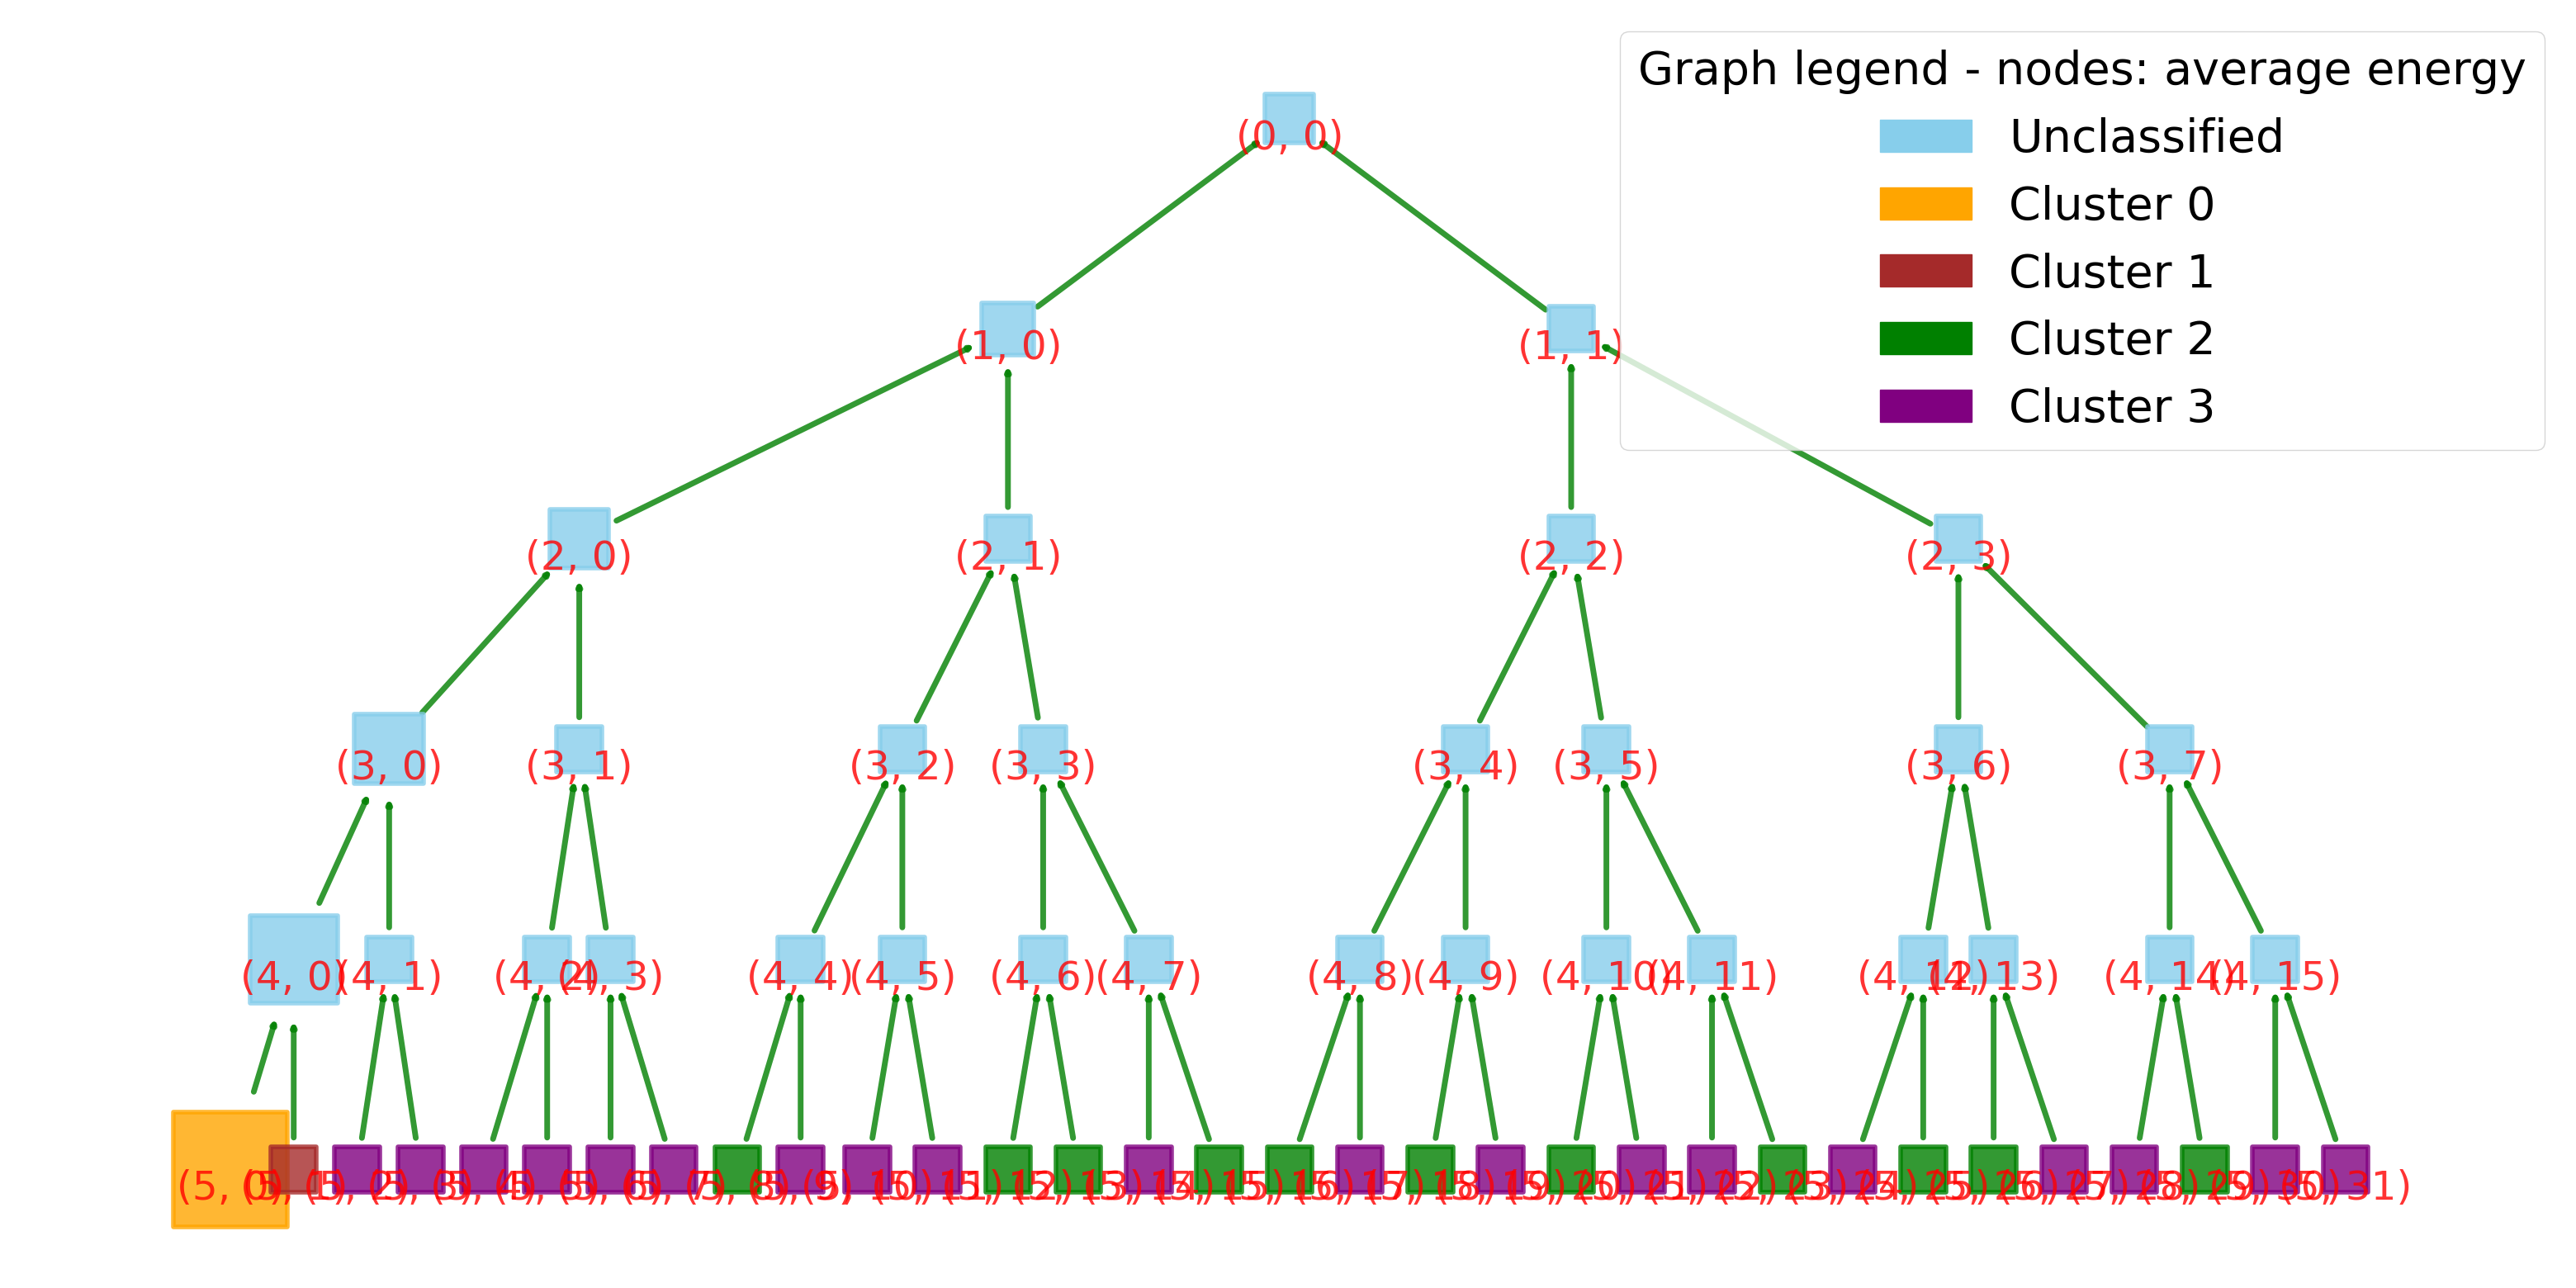

In [24]:
# tr_obj.calc_frequencies(sampling_rate)
# # if tr_obj.max_level() <= 7:
for i in range(n_cases):
    results_df[i]['tr_obj'].plot_tree(
        node_size="average energy", 
        node_colour=list(results_df[i]['labels_sorted']), 
        freq_threshold=freq_threshold, 
        graph_legend="Graph legend - nodes: average energy",
        fig_name=None,  # f"dwpt_graph_{results_df[i]['legend']}",
        sampling_rate=sampling_rate,  # calculate actual frequencys instead of normalised frequencies
        show_frequency=False  # whether to plot the frequency ranges of each node
)


In [25]:
for i in range(n_cases):
    fig_psd_rec_arb = plot.plot_fft_by_group(
        results_df[i]['tr_obj'], results_df[i]['labels_sorted'], sampling_rate=sampling_rate,
        clusters=None, 
        xlims=[0,fft_lim], 
        ylims=[-100,50],
        fundamental_freq=frequency,
        freq_threshold=freq_threshold, label_map=label_map_details[i],
        fig_height=Fig_Height,
        title = "FFT comparison - " + results_df[i]['legend']
    )
    if savefig_flag:
        fig_psd_rec_arb_name = "spectrum_rec_centeroids_arbitrary_GA_calculated_emissions_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
        print("figure name: " + fig_psd_rec_arb_name)
        save_figure(fig_psd_rec_arb, fig_psd_rec_arb_name, folder_path)
    
    fig_rec_arb = plot.plot_reconstructions_by_group(
        results_df[i]['tr_obj'], results_df[i]['labels_sorted'], t_plot=results_df[0]['t_data_truncated'], freq_threshold=freq_threshold, 
        fig_height=Fig_Height, title = "Reconstructed nodes by group - " + results_df[i]['legend']#, label_map=label_map_details[i] 
    )
    if savefig_flag:
        fig_rec_arb_name = "sig_rec_centeroids_arbitrary_GA_calculated_emissions_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
        print("figure name: " + fig_rec_arb_name)
        save_figure(fig_rec_arb, fig_rec_arb_name, folder_path)

pca results

In [26]:
if save_results_flag:
    for i in range(n_cases):
        file_name="results_GA_calculated_emissions_arbitrary clusters_"+results_df[i]['legend']+f"_freq:{frequency*1e-6:.1f}MHz_Pac:{pac*1e-6:.1f}MPa"
        file_name = file_name.replace(".","p")
        file_path = os.path.join(folder_path, file_name + ".pkl")
        with open(file_path, "wb") as file:
            # results_df[i].update(bd_params)
            pickle.dump(results_df[i], file)

separately plot reconstructions of all nodes belonging to selected clusters

In [27]:
import wavelet_transform.utils.statistical_features as sf


i=1
rec_high_kurt, rec_low_kurt = plot.get_reconstructions_by_threshold(
    results_df[i]['tr_obj'], feature="kurtosis", threshold=threshold, freq_threshold=freq_threshold
)

fig = go.Figure()
fig.add_trace(go.Scatter(
    # x=freq, 
    y=results_df[i]['tr_obj'].data,
    mode='lines',
    name="original signal"
))
fig.add_trace(go.Scatter(
    # x=freq, 
    y=rec_high_kurt,
    mode='lines',
    name="high kurtosis reconstruction of all nodes thresholded (kurtosis of wavelet coefficients)"
))
fig.add_trace(go.Scatter(
    # x=freq, 
    y=rec_low_kurt,
    mode='lines',
    name="low kurtosis reconstruction of all nodes thresholded (kurtosis of wavelet coefficients)"
))
fig.show()

# rec_high_kurt2, rec_low_kurt2 = plot.get_reconstructions_by_threshold(
#     results_df[i]['tr_obj'], feature=sf.kurtosis, threshold=threshold, freq_threshold=freq_threshold
# )
# fig2 = go.Figure()
# fig2.add_trace(go.Scatter(
#     # x=freq, 
#     y=results_df[i]['tr_obj'].data,
#     mode='lines',
#     name="original signal"
# ))
# fig2.add_trace(go.Scatter(
#     # x=freq, 
#     y=rec_high_kurt2,
#     mode='lines',
#     name="high kurtosis reconstruction (reconstruction kurtosis)"
# ))
# fig2.add_trace(go.Scatter(
#     # x=freq, 
#     y=rec_low_kurt2,
#     mode='lines',
#     name="low kurtosis reconstruction (reconstruction kurtosis)"
# ))
# fig2.show()

In [28]:
import wavelet_transform.wpt.inverse_transform as inv
import matplotlib.pyplot as plt

plot_centres = np.arange(len(results_df[i]['centers_sorted'])) 
plot_centres = plot_centres[results_df[i]['centers_sorted']['kurtosis']>threshold]
# Add number to plot_centres to plot reconstructions of all nodes belonging to the cluster
# plot_centres = [1]


reconstructions = [np.zeros(len(results_df[i]['tr_obj'].data)) for _ in range(2)]

# plt.figure()
for ii, (node, assignment) in enumerate(zip(results_df[i]['tr_obj'].get_leaf_nodes(freq_threshold=freq_threshold), 
                                            results_df[i]['labels_sorted'])):
    if assignment in plot_centres:
        # List reconstructions
        j = 0 if node.kurtosis > threshold else 1  # shorten name for readability
        print("kurtosis:", node.kurtosis, "\n assignment:",assignment," \n j:",j,"ii",ii)
        rec_signal = inv.inv_dwpt(results_df[i]['tr_obj'], node.level, nodes=node)
        reconstructions[j] = reconstructions[j] + rec_signal
        # psd_rec, freq = psd(rec, sampling_rate, frequency)
        # freq /= frequency
        # plt.plot(frequency, to_dB(psd_rec))
        # plt.xlim(0, fft_lim)
        # plt.title(f"frequency range: {np.divide(node.frequency_range,frequency)} (normalised by f0)")
        # plt.show()
        # plt.plot(reconstructions[0])
        # plt.plot(reconstructions[1])
        # plt.show()

# fig = go.Figure()
fig.add_trace(
    go.Scatter(
        y=reconstructions[0],
        mode="lines",
        name="higher than threshold-clusters",
    )
)
fig.add_trace(
    go.Scatter(
        y=reconstructions[1],
        mode="lines",
        name="lower than threshold-clusters",
    )
)


kurtosis: 2.508460767524285 
 assignment: 1  
 j: 1 ii 1
kurtosis: 4.615993816505519 
 assignment: 1  
 j: 0 ii 2
kurtosis: 4.928560562860384 
 assignment: 1  
 j: 0 ii 3
kurtosis: 4.793323204385568 
 assignment: 2  
 j: 0 ii 4
kurtosis: 3.2024022484409858 
 assignment: 1  
 j: 0 ii 5
kurtosis: 3.8768147131060546 
 assignment: 1  
 j: 0 ii 6
kurtosis: 5.614392122750391 
 assignment: 2  
 j: 0 ii 7
kurtosis: 6.22362202935392 
 assignment: 2  
 j: 0 ii 8
kurtosis: 3.51006091288325 
 assignment: 4  
 j: 0 ii 9
kurtosis: 5.676509455359293 
 assignment: 2  
 j: 0 ii 10
kurtosis: 5.569648451574819 
 assignment: 2  
 j: 0 ii 11
kurtosis: 4.60976430358423 
 assignment: 2  
 j: 0 ii 12
kurtosis: 3.1770798369459095 
 assignment: 4  
 j: 1 ii 13
kurtosis: 4.604510357313347 
 assignment: 2  
 j: 0 ii 14
kurtosis: 4.748389890762101 
 assignment: 2  
 j: 0 ii 15
kurtosis: 3.793174438523457 
 assignment: 4  
 j: 0 ii 16
kurtosis: 2.864406731297603 
 assignment: 4  
 j: 1 ii 17
kurtosis: 6.50573641602

In [29]:
results_df[i]['centers_sorted']

,index,log average energy,kurtosis,spectral entropy,average energy
0,1,12.548342,2.138133,0.439528,17.981845
1,4,-0.051541,3.826446,0.899270,1.072061
2,0,-4.530534,5.212862,0.914045,0.370791
3,3,-4.668790,8.487168,0.909319,0.341288
4,2,-5.485870,3.429339,0.917658,0.291915


In [30]:
psd_reconstructions_higher, freq_higher = psd(reconstructions[0], sampling_rate, frequency)
psd_reconstructions_lower, freq_lower = psd(reconstructions[1], sampling_rate, frequency)
psd_rec_all_kurt_thrsh_higher, freq2_higher = psd(rec_high_kurt, sampling_rate, frequency)
psd_rec_all_kurt_thrsh_lower, freq2_lower = psd(rec_low_kurt, sampling_rate, frequency)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=freq2_higher,
        y=to_dB(psd_rec_all_kurt_thrsh_higher),
        mode="lines",
        name="higher than threshold_all nodes",
    )
)
fig.add_trace(
    go.Scatter(
        x=freq_higher,
        y=to_dB(psd_reconstructions_higher),
        mode="lines",
        name="higher than threshold_ specified clusters",
    )
)


fig.add_trace(
    go.Scatter(
        x=freq2_lower,
        y=to_dB(psd_rec_all_kurt_thrsh_lower),
        mode="lines",
        name="lower than threshold_all nodes",
    )
)
fig.add_trace(
    go.Scatter(
        x=freq_lower,
        y=to_dB(psd_reconstructions_lower),
        mode="lines",
        name="lower than threshold_ specified clusters",
    )
)

fig.update_layout(
    xaxis=dict(title="f / f<sub>0</sub> [DL]", range=[0, 10]),
)

In [31]:
plot_centres

array([1, 2, 3, 4])

In [32]:
print("Energy of the HIGH-kurtosis broadband [dB]: ",sf.log_avg_energy(reconstructions[0]), 
      "\nEnergy of the LOW-kurtosis broadband [dB]:",sf.log_avg_energy(reconstructions[1]))

Energy of the HIGH-kurtosis broadband [dB]:  -4.52690013072475 
Energy of the LOW-kurtosis broadband [dB]: -10.452815948514608


In [33]:
print("Energy of the HIGH-kurtosis broadband [dB] - all node based calculation: ",sf.log_avg_energy(rec_high_kurt), 
      "\nEnergy of the LOW-kurtosis broadband [dB] - all node based calculation:",sf.log_avg_energy(rec_low_kurt))

Energy of the HIGH-kurtosis broadband [dB] - all node based calculation:  -4.52690013072475 
Energy of the LOW-kurtosis broadband [dB] - all node based calculation: -1.888427722231277


In [34]:
print("Spectral entropy of the HIGH-kurtosis broadband [dB]: ",sf.spectral_entropy(reconstructions[0]), 
      "\nSpectral entropy of the LOW-kurtosis broadband [dB]:",sf.spectral_entropy(reconstructions[1]))

Spectral entropy of the HIGH-kurtosis broadband [dB]:  0.9221848012796476 
Spectral entropy of the LOW-kurtosis broadband [dB]: 0.6718295954876604


In [35]:
print("Kurtosis of the HIGH-kurtosis broadband [dB]: ",sf.kurtosis(reconstructions[0]), 
      "\nKurtosis of the LOW-kurtosis broadband [dB]:",sf.kurtosis(reconstructions[1]))

Kurtosis of the HIGH-kurtosis broadband [dB]:  123.76979427315233 
Kurtosis of the LOW-kurtosis broadband [dB]: 7.788116557630337
